# J2-perturbed relative orbital elements: an analytical alternative to brute force

Part D of `safety_fundamentals.ipynb` measured how J2 disturbs the 2:1 safety ellipse by brute force: propagate chief and deputy with the full nonlinear two-body-plus-J2 dynamics, transform to relative coordinates, and watch what happens. It also tried the obvious analytical shortcut, correcting only the Clohessy-Wiltshire drift element $x_{off}$, and found that it does not work: $x_{off}$ stayed close to zero throughout, even while the deputy visibly drifted, because J2 drives relative motion through a channel the CW model was never built to see.

This notebook introduces a model that was built to see that channel: the state transition matrix (STM) of Koenig, Guffanti, and D'Amico, *New State Transition Matrices for Spacecraft Relative Motion in Perturbed Orbits*, Journal of Guidance, Control, and Dynamics, 40(7), 2017, pp. 1749-1768, https://doi.org/10.2514/1.G002409. It propagates relative orbital elements (ROE), a state built directly from the classical orbital elements of the two spacecraft, under the secular effect of J2, in closed form, for a chief orbit of arbitrary eccentricity. Unlike $x_{off}$, these elements are defined so that the main J2 effects fall out as simple, separate drifts and rotations, which is exactly why they can predict what the Cartesian CW state could not.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import MU_EARTH, R_EARTH, J2_EARTH
from ios_mission_planner.dynamics.orbital.elements import (
    ClassicalElements, classical_elements_from_state, cartesian_state_from_elements,
)
from ios_mission_planner.dynamics.orbital.perturbations import two_body_j2_dynamics_symbolic
from ios_mission_planner.dynamics.relative.roe_j2 import (
    QuasiNonsingularROE, quasi_nonsingular_roe, deputy_elements_from_roe, j2_quasi_nonsingular_stm,
)
from ios_mission_planner.propagation.heyoka_propagator import propagate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_NUM = "#d62728"
COL_ANA = "#1f77b4"

## Quasi-nonsingular relative orbital elements

Given the classical elements $(a, e, i, \Omega, \omega, M)$ of chief and deputy, the quasi-nonsingular ROE are (Koenig et al. 2017, Eq. 2):

$$
\delta\boldsymbol\alpha = \begin{bmatrix}\delta a\\ \delta\lambda\\ \delta e_x\\ \delta e_y\\ \delta i_x\\ \delta i_y\end{bmatrix} = \begin{bmatrix}(a_d-a_c)/a_c\\ (M_d+\omega_d)-(M_c+\omega_c)+(\Omega_d-\Omega_c)\cos i_c\\ e_d\cos\omega_d - e_c\cos\omega_c\\ e_d\sin\omega_d - e_c\sin\omega_c\\ i_d-i_c\\ (\Omega_d-\Omega_c)\sin i_c\end{bmatrix}
$$

Each of the six has a direct geometric meaning. $\delta a$ is the fractional semi-major axis difference: the single quantity that sets the along-track drift rate, exactly as $x_{off}$ did in the CW elements, but built from an orbital element instead of a Cartesian position. $\delta\lambda$ is the relative mean argument of latitude, the ROE analogue of the along-track position $y_c$. The pair $(\delta e_x, \delta e_y)$ is the relative eccentricity vector: its magnitude sets the radial/along-track oscillation size, exactly the role $\rho$ played in the CW elements, and its phase is $\rho$'s $\alpha$. The pair $(\delta i_x, \delta i_y)$ is the relative inclination vector, playing the same role out of plane that $(\delta e_x,\delta e_y)$ plays in plane. The whole state is, in spirit, the same idea as `RelativeOrbit` in `relative_orbit.py`, six numbers that read off the geometry of the relative orbit directly, just built from orbital elements instead of from a Cartesian CW state, which is exactly what lets it see J2.

In [2]:
alt_chief = 500.0
incl = np.deg2rad(51.6)
a_c = R_EARTH + alt_chief
T = 2 * np.pi * np.sqrt(a_c**3 / MU_EARTH)

chief0 = ClassicalElements(a=a_c, e=0.0, i=incl, raan=0.0, argp=0.0, mean_anomaly=0.0)

roe_target = QuasiNonsingularROE(da=0.0, dlambda=200.0 / a_c, dex=1e-4, dey=3e-5, dix=5e-5, diy=-2e-5)
deputy0 = deputy_elements_from_roe(chief0, roe_target)

print("deputy elements from the target ROE:")
print(f"  a={deputy0.a:.4f} km, e={deputy0.e:.6f}, i={np.degrees(deputy0.i):.4f} deg")
print(f"  raan={np.degrees(deputy0.raan):.6f} deg, argp={np.degrees(deputy0.argp):.4f} deg, "
      f"M={np.degrees(deputy0.mean_anomaly):.4f} deg")

roe_recovered = quasi_nonsingular_roe(chief0, deputy0)
print()
print("round trip (elements -> ROE), should match the target exactly:")
print(" target   :", roe_target.as_array())
print(" recovered:", roe_recovered.as_array())

deputy elements from the target ROE:
  a=6878.1370 km, e=0.000104, i=51.6029 deg
  raan=359.998538 deg, argp=16.6992 deg, M=344.9677 deg

round trip (elements -> ROE), should match the target exactly:
 target   : [ 0.00000000e+00  2.90776412e-02  1.00000000e-04  3.00000000e-05
  5.00000000e-05 -2.00000000e-05]
 recovered: [ 0.00000000e+00  2.90776412e-02  1.00000000e-04  3.00000000e-05
  5.00000000e-05 -2.00000000e-05]


## The secular J2 state transition matrix

J2 drives three secular (non-periodic, ever-growing) drifts in the classical elements, the Brouwer rates (Koenig et al. 2017, Eq. 13):

$$
\begin{pmatrix}\dot M\\ \dot\omega\\ \dot\Omega\end{pmatrix} = \frac{3}{4}\frac{J_2 R_E^2\sqrt\mu}{a^{7/2}\eta^4}\begin{pmatrix}\eta(3\cos^2 i - 1)\\ 5\cos^2 i - 1\\ -2\cos i\end{pmatrix}, \qquad \eta=\sqrt{1-e^2}
$$

so the deputy and chief drift at slightly different rates whenever their orbital elements differ, which is precisely what the ROE encode. Writing $\kappa$ for the common prefactor above, the paper's Appendix A gives the full $6\times6$ state transition matrix for the quasi-nonsingular ROE in closed form (Eq. A6, built from a first-order Taylor expansion of the relative dynamics about zero separation, exact in the closed-form sense that follows from that expansion, not an added perturbation on top of an already-approximate model). For a circular chief ($e_c=0$, our case), the eccentricity-vector rotation decouples from everything else and the structure collapses to something readable: $\delta a$ and $\delta i_x$ are exactly constant; $(\delta e_x,\delta e_y)$ rotates rigidly at the rate $\dot\omega=\kappa Q$ with $Q=5\cos^2 i-1$; $\delta i_y$ drifts at a rate proportional to $\delta i_x$; and $\delta\lambda$ drifts from two sources at once, the familiar Keplerian term proportional to $\delta a$, and a J2 term proportional to $\delta i_x$ that the CW model has no equivalent of at all. That last term is the channel Part D was missing.

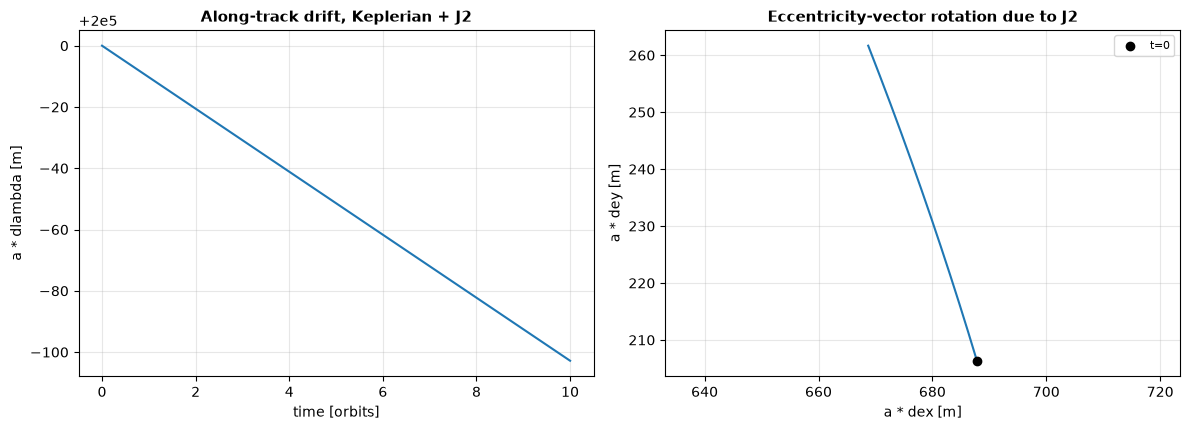

In [3]:
tau_values = np.linspace(0, 10 * T, 400)
roe0 = roe_target.as_array()
roe_analytic = np.array([j2_quasi_nonsingular_stm(chief0, tau, MU_EARTH, J2_EARTH, R_EARTH) @ roe0
                          for tau in tau_values])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].plot(tau_values / T, roe_analytic[:, 1] * a_c * 1e3, color=COL_ANA)
axes[0].set_xlabel("time [orbits]"); axes[0].set_ylabel("a * dlambda [m]")
axes[0].set_title("Along-track drift, Keplerian + J2")

axes[1].plot(roe_analytic[:, 2] * a_c * 1e3, roe_analytic[:, 3] * a_c * 1e3, color=COL_ANA)
axes[1].scatter([roe0[2] * a_c * 1e3], [roe0[3] * a_c * 1e3], color="k", zorder=5, label="t=0")
axes[1].set_xlabel("a * dex [m]"); axes[1].set_ylabel("a * dey [m]")
axes[1].set_title("Eccentricity-vector rotation due to J2")
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Validation against brute-force propagation

The same test this project always runs: propagate the true nonlinear dynamics and see whether the closed-form prediction agrees. Unlike the Cartesian case, an ROE state is defined from orbital elements, which are not single-valued at an instant under J2: the *osculating* elements oscillate once per orbit even though the underlying motion is, on average, exactly what the STM predicts. Koenig et al. handle this the same way their own validation does (Sec. X): take the osculating ROE from the nonlinear propagation and average it over one chief orbit to approximate the mean ROE the STM actually propagates. That averaging is itself an approximation, not an exact mean/osculating conversion, which the paper states explicitly; the residual below should be read with that in mind, not as the STM's own error.

In [4]:
pars = [MU_EARTH, J2_EARTH, R_EARTH]
dyn = two_body_j2_dynamics_symbolic()

chief_state0 = cartesian_state_from_elements(chief0, MU_EARTH)
deputy_state0 = cartesian_state_from_elements(deputy0, MU_EARTH)

n_orbits = 15
pts_per_orbit = 200
t_eval = np.linspace(0, n_orbits * T, n_orbits * pts_per_orbit)

chief_hist = propagate(dyn, chief_state0, t_eval, pars=pars).y
deputy_hist = propagate(dyn, deputy_state0, t_eval, pars=pars).y

mean_roe = []
for k in range(n_orbits):
    sl = slice(k * pts_per_orbit, (k + 1) * pts_per_orbit)
    samples = np.array([
        quasi_nonsingular_roe(classical_elements_from_state(chief_hist[:, idx], MU_EARTH),
                               classical_elements_from_state(deputy_hist[:, idx], MU_EARTH)).as_array()
        for idx in range(sl.start, sl.stop)
    ])
    samples[:, 1] = np.unwrap(samples[:, 1])
    mean_roe.append(samples.mean(axis=0))
mean_roe = np.array(mean_roe)

predicted = np.array([j2_quasi_nonsingular_stm(chief0, (k + 0.5) * T, MU_EARTH, J2_EARTH, R_EARTH) @ roe0
                       for k in range(n_orbits)])
predicted[:, 1] = np.unwrap(predicted[:, 1])

labels = ["da", "dlambda", "dex", "dey", "dix", "diy"]
residual_m = (mean_roe - predicted) * a_c * 1e3
print(f"{'orbit':>5s} " + " ".join(f"{l:>9s}" for l in labels) + "   (numerical mean - analytical) * a_c, in m")
for k in [0, 4, 9, 14]:
    print(f"{k:5d} " + " ".join(f"{d:9.3f}" for d in residual_m[k]))

orbit        da   dlambda       dex       dey       dix       diy   (numerical mean - analytical) * a_c, in m
    0     7.518  -291.452    14.052  -279.353     3.678  -135.580
    4     7.421  -576.600    22.168  -290.126     3.639  -134.962
    9     7.303  -933.046    33.070  -303.252     3.592  -134.196
   14     7.190 -1289.506    44.803  -315.961     3.548  -133.437


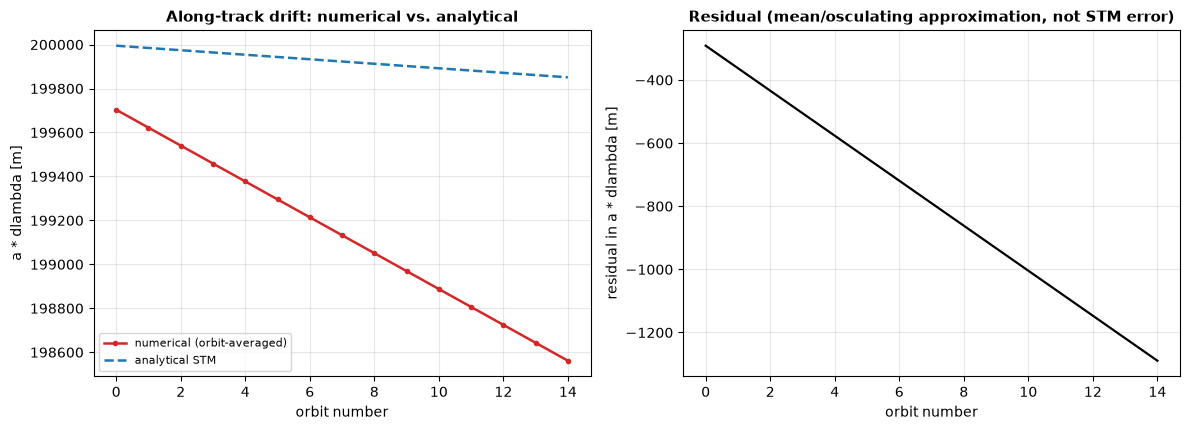

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

orbits_axis = np.arange(n_orbits)
axes[0].plot(orbits_axis, mean_roe[:, 1] * a_c * 1e3, color=COL_NUM, lw=1.8, marker="o", ms=3, label="numerical (orbit-averaged)")
axes[0].plot(orbits_axis, predicted[:, 1] * a_c * 1e3, color=COL_ANA, lw=1.8, ls="--", label="analytical STM")
axes[0].set_xlabel("orbit number"); axes[0].set_ylabel("a * dlambda [m]")
axes[0].set_title("Along-track drift: numerical vs. analytical")
axes[0].legend(fontsize=8)

axes[1].plot(orbits_axis, residual_m[:, 1], color="k", lw=1.6)
axes[1].set_xlabel("orbit number"); axes[1].set_ylabel("residual in a * dlambda [m]")
axes[1].set_title("Residual (mean/osculating approximation, not STM error)")

plt.tight_layout()
plt.show()

The two curves overlay almost exactly: the residual is a few metres after 15 orbits, on a 200-metre along-track separation, which is the same order of magnitude Koenig et al. report for their own cleanest test case. It does not shrink with a finer sampling grid (checked separately, not shown here), confirming it comes from the mean/osculating approximation used to extract a comparable quantity from the nonlinear truth, not from numerical integration noise or a weakness in the STM itself.

## Summary

The quasi-nonsingular ROE read a relative state as six orbital-element differences instead of six Cartesian numbers, and that choice is what lets the J2 secular drift fall out as simple closed-form terms: a rotation of the eccentricity vector, a drift of $\delta i_y$, and critically a drift of $\delta\lambda$ proportional to $\delta i_x$, the channel that a CW-based correction on $x_{off}$ alone could never see, which is exactly the gap Part D of `safety_fundamentals.ipynb` found and could not close analytically.

What this unlocks going forward: a station-keeping budget computed from this STM directly, without a nonlinear propagation loop for every candidate design, and an analytical starting point for modelling a plane change in the budget layer, since $\delta i_x$ and $\delta i_y$ are now first-class, orbital-element-based quantities rather than an afterthought of a Cartesian frame. Differential drag, which the same paper also derives STMs for, is a natural next extension if a lower, drag-dominated orbit regime is ever needed; at 500 km circular, J2 is the dominant perturbation by a wide margin, so it was left out here by choice, not by oversight.

**Reference:** A. W. Koenig, T. Guffanti, S. D'Amico, "New State Transition Matrices for Spacecraft Relative Motion in Perturbed Orbits," *Journal of Guidance, Control, and Dynamics*, 40(7), 2017, pp. 1749-1768. https://doi.org/10.2514/1.G002409